# Passo 6 – Hiperparâmetros da árvore

Cenário fixo: **WIN, 60 min, janela 36 meses, re-treino trimestral, 17 variáveis, regra "|previsto| > custo (5 pts)"**. Avaliado na validação 2024.

| Hiperparâmetro | O que controla | Grade |
|---|---|---|
| `max_depth` | nº máximo de perguntas em sequência em cada árvore | 3, 4, 6, 8, 12 |
| `min_samples_leaf` | fração mínima de candles em cada folha | 0,1%, 0,5%, 1%, 2%, 5% |
| `max_features` | fração de variáveis sorteadas em cada divisão | 0,33, 0,5, 1,0 |
| `n_estimators` | nº de árvores | 300 (fixo) |

**Intuição:** árvore profunda + folha pequena = modelo flexível, que pode **decorar ruído**; árvore rasa + folha grande = modelo rígido, que pode **não ver o padrão**. Com o sinal fraco do Passo 2, esperamos que modelos mais rígidos se saiam melhor.

**Escolha:** em vez de pegar a melhor célula (que pode ser sorte entre 75), pegamos a de melhor **média na vizinhança** (ela e as combinações vizinhas de profundidade e folha). Uma região inteira boa é mais confiável que um pico isolado.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os, time, itertools
from sklearn.ensemble import RandomForestRegressor
import rf_zero as rz
win_1m = rz.carregar("../../dados/WINN_M1/WIN$N_M1.csv")
base, cols = rz.montar_base(win_1m, 60)
PROF = [3, 4, 6, 8, 12]; FOLHA = [0.001, 0.005, 0.01, 0.02, 0.05]; MF = [0.33, 0.5, 1.0]
ARQ = "saidas/passo06_previsoes.pkl"
prevs = pd.read_pickle(ARQ) if os.path.exists(ARQ) else {}
t0 = time.time()
for p, f, mf in itertools.product(PROF, FOLHA, MF):
    if (p, f, mf) in prevs: continue
    fab = lambda n, p=p, f=f, mf=mf: RandomForestRegressor(n_estimators=300, max_depth=p, min_samples_leaf=f,
                                                         max_features=mf, n_jobs=-1, random_state=42)
    prevs[(p, f, mf)] = rz.walk_forward(base, cols, rz.VALIDACAO, 36, "QS", fabrica=fab)[["prev", "ret_prox", "mov_prox", "close"]]
pd.to_pickle(prevs, ARQ)
print(f"{len(prevs)} combinações, {time.time() - t0:.0f} s")

75 combinações, 179 s


In [2]:
def avaliar_regra(d):
    pts = rz.prev_pontos(d)
    dirc = np.sign(pts).where(pts.abs() > rz.CUSTO_PTS, 0)
    op = dirc != 0
    res = rz.resultado_operacoes(dirc.values, d["mov_prox"].values)
    r = rz.resumo_ops(res, d.index[op.values])
    sinal = rz.avaliar(d["prev"].values, d)
    r["R² %"] = sinal["R² vs naive %"]; r["ganho bruto (sempre)"] = sinal["ganho bruto pts/op"]
    r["|previsto| mediano pts"] = pts.abs().median()
    return r

grade = pd.DataFrame({k: avaliar_regra(v) for k, v in prevs.items()}).T
grade.index.names = ["prof", "folha", "max_feat"]
# média na vizinhança: a própria célula e as vizinhas (±1 posição em profundidade e em folha), mesmo max_features
def vizinhanca(col):
    out = {}
    for (p, f, mf) in grade.index:
        i, j = PROF.index(p), FOLHA.index(f)
        viz = [(PROF[a], FOLHA[b], mf) for a in range(max(i-1, 0), min(i+2, len(PROF)))
                                          for b in range(max(j-1, 0), min(j+2, len(FOLHA)))]
        out[(p, f, mf)] = grade.loc[viz, col].mean()
    return pd.Series(out)
grade["esperança vizinhança"] = vizinhanca("esperança pts/op")
grade["total R$ vizinhança"] = vizinhanca("total R$ (1 contrato)")
grade = grade.sort_index(); grade.to_csv("saidas/passo06_grade.csv")
mostrar = ["n_ops", "esperança pts/op", "t", "trimestres +", "total R$ (1 contrato)", "drawdown máx pts",
           "R² %", "|previsto| mediano pts", "esperança vizinhança", "total R$ vizinhança"]
grade[mostrar].round(2)

n_ops  esperança pts/op     t  trimestres +  \
prof folha max_feat                                                 
3    0.001 0.33      1178.0             15.72  1.70           4.0   
           0.50      1153.0             10.28  1.10           2.0   
           1.00      1164.0             10.86  1.19           3.0   
     0.005 0.33      1338.0             16.13  1.91           4.0   
           0.50      1422.0             15.41  1.89           3.0   
...                     ...               ...   ...           ...   
12   0.020 0.50      1747.0             10.87  1.46           4.0   
           1.00      1775.0              6.06  0.82           3.0   
     0.050 0.33      1652.0              8.20  1.08           4.0   
           0.50      1675.0             11.01  1.47           4.0   
           1.00      1710.0             12.99  1.74           4.0   

                     total R$ (1 contrato)  drawdown máx pts  R² %  \
prof folha max_feat                                                  
3    0.001 0.33                     3704.0            5905.0  0.26   
           0.50                     2371.0            6025.0  0.31   
           1.00                     2529.0            4775.0  0.39   
     0.005 0.33                     4316.0            5940.0  0.32   
           0.50                     4383.0            6345.0  0.33   
...                                    ...               ...   ...   
12   0.020 0.50                     3798.0            6735.0 -0.03   
           1.00                     2152.0           11705.0 -0.29   
     0.050 0.33                     2708.0            4650.0  0.30   
           0.50                     3690.0            4825.0  0.33   
           1.00                     4442.0            4290.0  0.30   

                     |previsto| mediano pts  esperança vizinhança  \
prof folha max_feat                                                 
3    0.001 0.33                        6.13                 14.07   
           0.50                        5.82                 12.94   
           1.00                        5.87                 10.16   
     0.005 0.33                        7.71                 13.23   
           0.50                        8.06                 12.91   
...                                     ...                   ...   
12   0.020 0.50                       20.97                 11.31   
           1.00                       22.75                  8.26   
     0.050 0.33                       15.01                  7.57   
           0.50                       16.75                 11.41   
           1.00                       18.53                  9.57   

                     total R$ vizinhança  
prof folha max_feat                       
3    0.001 0.33                  3719.75  
           0.50                  3547.00  
           1.00                  2774.75  
     0.005 0.33                  3604.83  
           0.50                  3643.50  
...                                  ...  
12   0.020 0.50                  3850.33  
           1.00                  2846.00  
     0.050 0.33                  2547.25  
           0.50                  3876.25  
           1.00                  3294.75  

[75 rows x 10 columns]

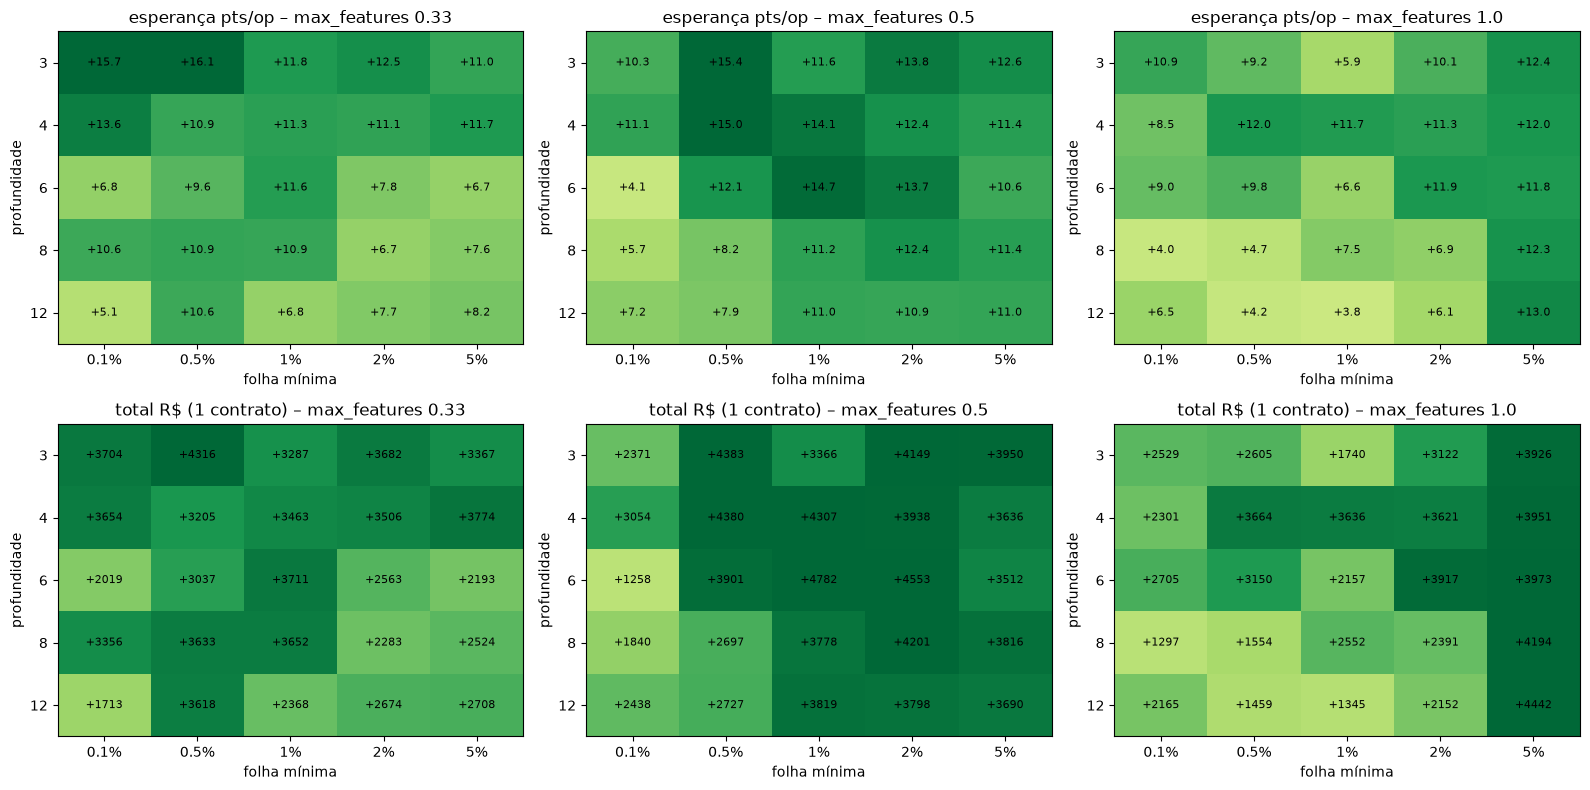

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(16, 8))
for linha, (col, vmin, vmax, fmt) in enumerate([("esperança pts/op", -15, 15, "{:+.1f}"), ("total R$ (1 contrato)", -4000, 4000, "{:+.0f}")]):
    for a, mf in zip(axs[linha], MF):
        g = grade.xs(mf, level="max_feat")[col].unstack("folha")
        im = a.imshow(g.values, cmap="RdYlGn", vmin=vmin, vmax=vmax, aspect="auto")
        for i in range(g.shape[0]):
            for k in range(g.shape[1]):
                a.text(k, i, fmt.format(g.values[i, k]), ha="center", va="center", fontsize=8)
        a.set_xticks(range(len(FOLHA))); a.set_xticklabels([f"{x*100:g}%" for x in FOLHA])
        a.set_yticks(range(len(PROF))); a.set_yticklabels(PROF)
        a.set_xlabel("folha mínima"); a.set_ylabel("profundidade"); a.set_title(f"{col} – max_features {mf}")
plt.tight_layout(); plt.savefig("passo06_hiperparametros.png", dpi=120); plt.show()

In [4]:
# Qual hiperparâmetro pesa mais? média por nível
pd.concat({d: grade.groupby(level=d)[["esperança pts/op", "total R$ (1 contrato)", "R² %", "n_ops"]].mean()
           for d in ["prof", "folha", "max_feat"]}).round(2)

esperança pts/op  total R$ (1 contrato)  R² %    n_ops
prof     3.000              11.96                3366.47  0.35  1412.47
         4.000              11.87                3606.00  0.33  1518.33
         6.000               9.78                3162.07  0.17  1608.13
         8.000               8.74                2917.87 -0.04  1665.93
         12.000              7.99                2741.07 -0.44  1717.33
folha    0.001               8.61                2426.93  0.00  1461.80
         0.005              10.45                3221.93 -0.10  1570.60
         0.010              10.02                3197.53  0.01  1608.27
         0.020              10.35                3370.00  0.11  1640.87
         0.050              10.90                3577.07  0.36  1640.67
max_feat 0.330              10.13                3120.40  0.09  1567.96
         0.500              11.18                3533.76  0.11  1586.04
         1.000               8.88                2821.92  0.02  1599.32

In [5]:
cand = grade[(grade["trimestres +"] >= 3) & (grade["esperança pts/op"] > 0)]
print("Top 8 pela esperança média na vizinhança (entre as que têm ≥ 3 trimestres positivos):")
display(cand.sort_values("esperança vizinhança", ascending=False)[mostrar].head(8).round(2))
print("Referência – RF do Passo 5 (prof 6, folha 0,5%, max_features 0,5):")
display(grade.loc[[(6, 0.005, 0.5)], mostrar].round(2))

Top 8 pela esperança média na vizinhança (entre as que têm ≥ 3 trimestres positivos):


n_ops  esperança pts/op     t  trimestres +  \
prof folha max_feat                                                 
3    0.001 0.33      1178.0             15.72  1.70           4.0   
     0.010 0.50      1451.0             11.60  1.44           3.0   
4    0.010 0.50      1532.0             14.06  1.76           4.0   
3    0.005 0.33      1338.0             16.13  1.91           4.0   
           0.50      1422.0             15.41  1.89           3.0   
4    0.020 0.50      1592.0             12.37  1.57           3.0   
3    0.020 0.50      1503.0             13.80  1.72           3.0   
6    0.010 0.50      1629.0             14.68  1.89           3.0   

                     total R$ (1 contrato)  drawdown máx pts  R² %  \
prof folha max_feat                                                  
3    0.001 0.33                     3704.0            5905.0  0.26   
     0.010 0.50                     3366.0            5175.0  0.43   
4    0.010 0.50                     4307.0            5950.0  0.38   
3    0.005 0.33                     4316.0            5940.0  0.32   
           0.50                     4383.0            6345.0  0.33   
4    0.020 0.50                     3938.0            5630.0  0.32   
3    0.020 0.50                     4149.0            7325.0  0.41   
6    0.010 0.50                     4782.0            5965.0  0.16   

                     |previsto| mediano pts  esperança vizinhança  \
prof folha max_feat                                                 
3    0.001 0.33                        6.13                 14.07   
     0.010 0.50                        8.96                 13.70   
4    0.010 0.50                       10.69                 13.63   
3    0.005 0.33                        7.71                 13.23   
           0.50                        8.06                 12.91   
4    0.020 0.50                       12.23                 12.75   
3    0.020 0.50                       10.48                 12.64   
6    0.010 0.50                       14.21                 12.62   

                     total R$ vizinhança  
prof folha max_feat                       
3    0.001 0.33                  3719.75  
     0.010 0.50                  4087.17  
4    0.010 0.50                  4195.44  
3    0.005 0.33                  3604.83  
           0.50                  3643.50  
4    0.020 0.50                  4021.44  
3    0.020 0.50                  3891.00  
6    0.010 0.50                  4059.67

Referência – RF do Passo 5 (prof 6, folha 0,5%, max_features 0,5):


,,,n_ops,esperança pts/op,t,trimestres +,total R$ (1 contrato),drawdown máx pts,R² %,|previsto| mediano pts,esperança vizinhança,total R$ vizinhança
prof,folha,max_feat,,,,,,,,,,
6,0.005,0.5,1615.0,12.08,1.56,4.0,3901.0,5955.0,-0.04,12.61,10.68,3333.0


## Conclusões do Passo 6

1. **O resultado é robusto aos hiperparâmetros:** as **75 combinações** têm esperança líquida positiva (de +3,8 a +16,1 pts/op). O lucro não depende de uma configuração "mágica" – ele vem das escolhas dos Passos 3–5 (candle, janela, regra).
2. **Árvores rasas são melhores.** Profundidade 3–4: esperança média ~12 pts/op e R² de +0,35%; profundidade 12: ~8 pts/op e R² de −0,44%. Exatamente o esperado com sinal fraco: árvore profunda decora ruído.
3. **Folha maior ajuda** (0,1% → 5%: esperança média 8,6 → 10,9; R² 0,00 → +0,36%). Folhas grandes amortecem os candles extremos (caudas pesadas do Passo 2).
4. **max_features 0,5 é o melhor** dos três (média 11,2 contra 10,1 e 8,9). Sortear metade das variáveis deixa as árvores mais diferentes entre si, e a média delas fica mais estável.
5. **Escolha: profundidade 4, folha 1%, max_features 0,5** → +14,1 pts/op, t = 1,8, **4/4 trimestres**, **R$ 4.307**, R² = +0,38%. Pela esperança média na vizinhança ela empata com prof 3 / folha 0,1% / mf 0,33 (13,6 × 14,1 – diferença dentro do ruído); desempatamos pela **vizinhança com maior lucro total** (R$ 4.195, a maior da grade) e por estar no **meio** da região boa (prof 3–4, folha 0,5–2%), não num canto da grade.
6. **Ganho sobre a RF do Passo 5 é modesto:** +12,1 → +14,1 pts/op. Hiperparâmetros são ajuste fino; não transformam um modelo ruim em bom.

➡️ **Modelo congelado para o teste:** WIN · 60 min · janela 36 m · re-treino trimestral · 17 variáveis · RF(300 árvores, prof 4, folha 1%, max_features 0,5) · treino sem custo · opera se |previsto| > 5 pts.
